# Figure 7 — observed shapes compared with native NISP

This is the single active Figure 7 notebook, replacing the former 7 and 7b.
The main figure compares diffusion, ResNet and ResNet-D5 with observed JWST shapes;
identical native-NISP-versus-JWST contours appear in every column. The companion
summary retains interpolation baselines, mean-of-three diffusion, adaptive moments,
and full-population measurement success.

The frozen Figure 6 predictions and existing JWST/model measurements are unchanged.
Native NISP is measured on its original grid, with the same angular aperture and
Gaussian weight (pixel step 5). Native uses its own validity mask; cached images
retain their common-valid mask. Each estimator uses the intersection of successful
JWST, native NISP and all six cached methods. No source-segmentation clipping,
PSF matching, inference, or test-set access. These are observed cross-band shapes,
not PSF-corrected shapes or calibrated shear.

Rebuild the versioned input with `python code/add_native_shape_comparison.py`
from the repository root in a fresh checkout without the v02 bundle/output directory.
The analyzer saves its contract and source snapshots before measuring native images.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from IPython.display import display
here=Path.cwd();workspace=here if (here/'figure_utils.py').exists() else here/'paper_figures'
if str(workspace) not in sys.path:sys.path.insert(0,str(workspace))
from figure_utils import ROOT,FIGURES,COLORS,style,read_json,sha,export
%matplotlib inline
style()
VERSION='v02'
path=FIGURES/'inputs'/f'cached_shapes_{VERSION}.json'
b=read_json(path)
assert b['complete'] and b['local_only']
assert sha(ROOT/b['arrays_path'])==b['arrays_sha256']
with np.load(ROOT/b['arrays_path']) as f:arrays={k:f[k] for k in f.files}
names=b['methods'];labels={'native':'Native NISP','bilinear':'Bilinear','bicubic':'Bicubic','diffusion':'Diffusion (1 sample)',
'diffusion_mean3':'Diffusion (mean of 3)','legacy':'ResNet','direct5':'ResNet-D5'}
colors={**COLORS,'diffusion_mean3':'#B485B8'}
print('Attempted:',len(b['object_ids']),'Common across both estimators:',b['cross_estimator_objects'])


Attempted: 2118 Common across both estimators: 1297


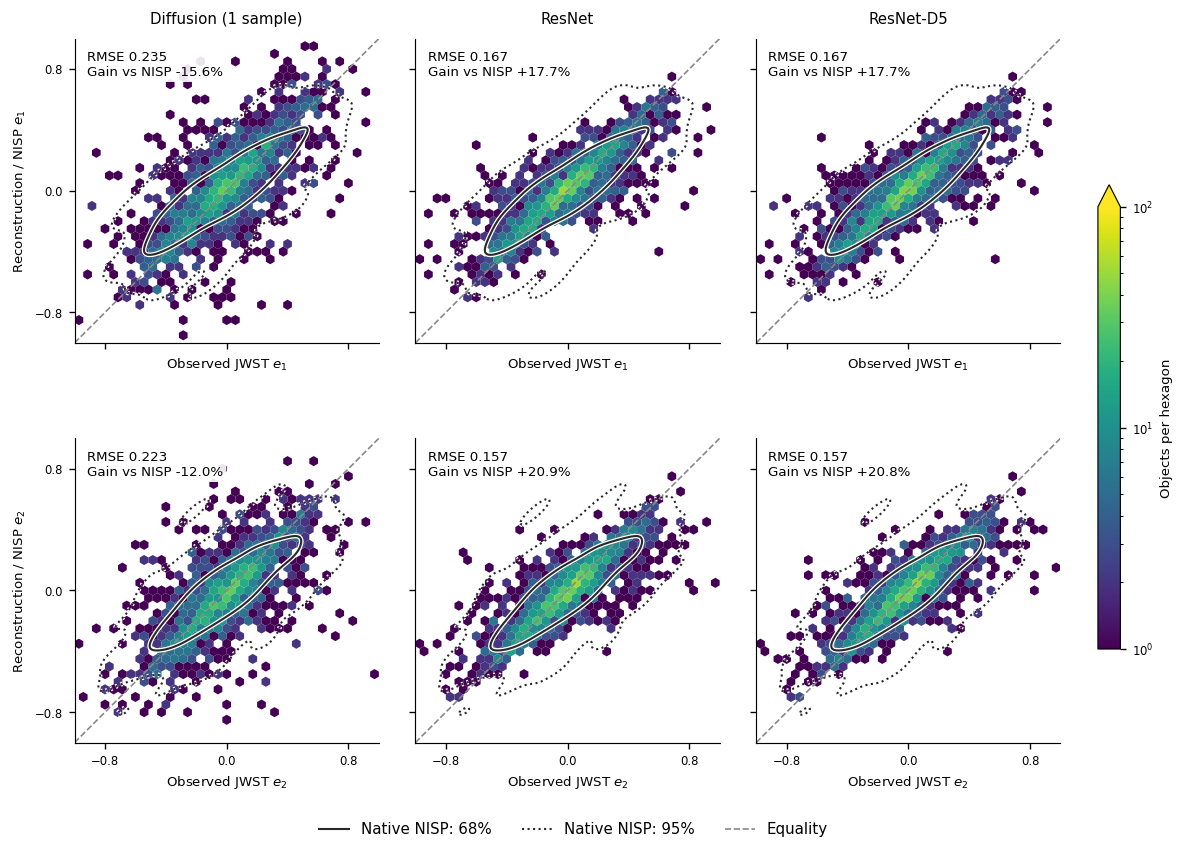

Exported: fig07_model_shape_agreement_v02.pdf, fig07_model_shape_agreement_v02.svg, fig07_model_shape_agreement_v02.png


[PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shape_agreement_v02.pdf'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shape_agreement_v02.svg'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shape_agreement_v02.png')]

In [2]:
# Main Figure 7: all panels use the same galaxies and native reference contours.
import matplotlib.patheffects as pe
case='fixed';summary=b['summaries'][case]
keep=np.isin(arrays['object_ids'],summary['object_ids'])
ref=arrays[f'{case}__target__e'][keep]
native=arrays[f'{case}__native__e'][keep]
fig,axes=plt.subplots(2,3,figsize=(10.4,7.3),sharex=True,sharey=True)
contour_color='#282828'
halo=[pe.Stroke(linewidth=2.8,foreground='white'),pe.Normal()]
for j,name in enumerate(['diffusion','legacy','direct5']):
    pred=arrays[f'{case}__{name}__e'][keep]
    for k in range(2):
        ax=axes[k,j]
        artist=ax.hexbin(ref[:,k],pred[:,k],gridsize=35,extent=(-1,1,-1,1),mincnt=1,
                         norm=LogNorm(vmin=1,vmax=100),cmap='viridis',linewidths=0)
        ax.plot([-1,1],[-1,1],color='#888888',ls='--',lw=1,zorder=2)
        # Stored highest-density levels are [68%,95%]; contour requires increasing levels.
        contours=ax.contour(arrays['contour_axis'],arrays['contour_axis'],
            arrays[f'contour_density_e{k+1}'],levels=arrays[f'contour_thresholds_e{k+1}'][::-1],
            colors=contour_color,linestyles=[':','-'],linewidths=1.25,zorder=3)
        contours.set_path_effects(halo)
        ax.set_xlim(-1,1);ax.set_ylim(-1,1);ax.set_aspect('equal')
        ax.set_xticks([-.8,0,.8]);ax.set_yticks([-.8,0,.8])
        delta=pred[:,k]-ref[:,k]
        gain=b['native_comparison'][case][name]['reduction_percent'][k+1]
        ax.text(.04,.96,f'RMSE {np.sqrt(np.mean(delta**2)):.3f}\nGain vs NISP {gain:+.1f}%',
                transform=ax.transAxes,va='top',fontsize=8,zorder=4,
                bbox=dict(facecolor='white',edgecolor='none',alpha=.9,pad=2))
        if k==0:ax.set_title(labels[name],pad=9)
        if j==0:ax.set_ylabel(rf'Reconstruction / NISP $e_{k+1}$')
        ax.set_xlabel(rf'Observed JWST $e_{k+1}$')
fig.subplots_adjust(left=.09,right=.88,top=.94,bottom=.13,wspace=.12,hspace=.29)
cax=fig.add_axes([.91,.24,.018,.53]);fig.colorbar(artist,cax=cax,label='Objects per hexagon',extend='max')
fig.legend(handles=[Line2D([],[],color=contour_color,ls='-',lw=1.25,label='Native NISP: 68%'),
                    Line2D([],[],color=contour_color,ls=':',lw=1.25,label='Native NISP: 95%'),
                    Line2D([],[],color='#888888',ls='--',lw=1,label='Equality')],
           loc='lower center',bbox_to_anchor=(.49,.01),ncol=3,frameon=False,fontsize=9)
plt.show()
export(fig,f'fig07_model_shape_agreement_{VERSION}','07_model_shapes.ipynb',
       [path,ROOT/b['arrays_path']],
       dict(estimator=case,objects=int(keep.sum()),methods=['diffusion','legacy','direct5'],
            contours=b['contours'],gain=b['gain'],population=b['population']),
       status='Figure 7: observed shape agreement with matched native NISP contours')


## Figure 7 caption

Observed ellipticity agreement with JWST F115W for diffusion (one sample), ResNet,
and ResNet-D5, with $e_1$ above and $e_2$ below. Hexagons show the number of galaxies
on a common logarithmic colour scale. Solid and dotted dark contours enclose 68%
and 95% of the smoothed native-NISP-versus-JWST joint distribution; the identical
contours are repeated across each row. Dashed grey lines indicate equality.
Fixed Gaussian-weighted moments use the same angular window on the native and
reconstructed grids. All panels and RMSE comparisons use the same galaxies with
successful measurements in JWST, native NISP, and all six cached methods.
The printed gain is $100(1-\mathrm{RMSE}_{\mathrm{model}}/\mathrm{RMSE}_{\mathrm{NISP}})$;
positive values mean lower error. Contours describe a joint distribution, not
confidence intervals on a fitted relation. Success counts and paired spatial-block
uncertainty are reported below. These observed cross-band shapes include differences
in instrumental PSFs and pixel sampling; they are not calibrated shear estimates.


In [3]:
print(f"Figure 7: {b['summaries']['fixed']['common_successes']:,} common successful objects / {len(b['object_ids']):,} attempted.")
rows=[]
for case in ['fixed','adaptive']:
    for name in ['native','diffusion','legacy','direct5']:
        rec=b['native_comparison'][case][name]
        rows.append(dict(estimator=case,method=labels[name],
            common_objects=b['summaries'][case]['common_successes'],
            successful_of_2118=b['summaries'][case]['success_counts'][name],
            component_rmse=rec['rmse'][0],gain_percent=rec['reduction_percent'][0],
            gain_ci95_percent=rec['ci95_percent'][0]))
display(pd.DataFrame(rows))


Figure 7: 1,446 common successful objects / 2,118 attempted.


,estimator,method,common_objects,successful_of_2118,component_rmse,gain_percent,gain_ci95_percent
0,fixed,Native NISP,1446,1741,0.201114,0.000000,"[0.0, 0.0]"
1,fixed,Diffusion (1 sample),1446,1633,0.228958,-13.844969,"[-16.03157423277367, -11.26577964635931]"
2,fixed,ResNet,1446,1786,0.162364,19.267582,"[16.591509333536603, 21.87278368654546]"
3,fixed,ResNet-D5,1446,1786,0.162494,19.203084,"[16.520554995929015, 21.64788704880936]"
4,adaptive,Native NISP,1498,1685,0.242377,0.000000,"[0.0, 0.0]"
5,adaptive,Diffusion (1 sample),1498,1678,0.296577,-22.362146,"[-27.807251658056707, -17.97281253539561]"
6,adaptive,ResNet,1498,1742,0.216657,10.611569,"[7.3468183709684, 13.219594509871527]"
7,adaptive,ResNet-D5,1498,1745,0.216849,10.532413,"[7.611552589936058, 13.020338502896005]"


## Companion diagnostic: both estimators and all attempted measurements

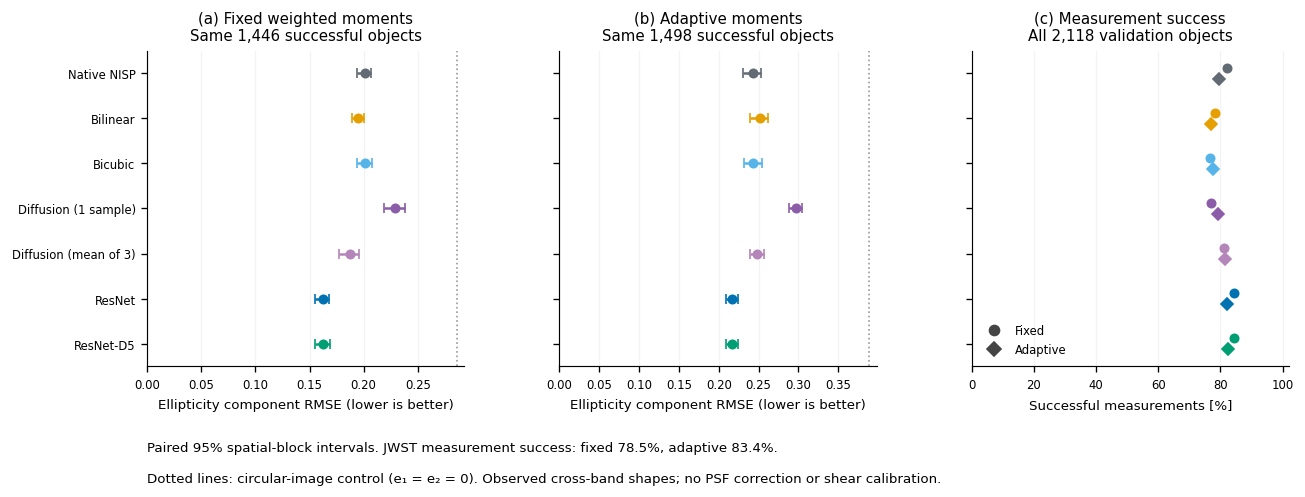

Exported: fig07_model_shapes_v02.pdf, fig07_model_shapes_v02.svg, fig07_model_shapes_v02.png


[PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v02.pdf'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v02.svg'),
 PosixPath('/home/shemmati/Work/Projects/superNISP/paper_figures/exports/fig07_model_shapes_v02.png')]

In [4]:
fig,axes=plt.subplots(1,3,figsize=(11.6,4.7),sharey=True)
y=np.arange(len(names))
for ax,case,title in zip(axes[:2],['fixed','adaptive'],['(a) Fixed weighted moments','(b) Adaptive moments']):
    summary=b['summaries'][case]
    for i,name in enumerate(names):
        rec=summary['methods'][name]['component_rmse'];value=rec['mean'];lo,hi=rec['ci95']
        ax.errorbar(value,i,xerr=np.array([[value-lo],[hi-value]]),fmt='o',color=colors[name],capsize=3,ms=5)
    control=summary['methods']['round_control']['component_rmse']['mean']
    ax.axvline(control,color='#999999',ls=':',lw=1)
    ax.set_xlim(left=0)
    ax.set_xlabel('Ellipticity component RMSE (lower is better)')
    ax.set_title(f"{title}\nSame {summary['common_successes']:,} successful objects")
axes[0].set_yticks(y,[labels[m] for m in names])
for case,marker,offset in [('fixed','o',-.12),('adaptive','D',.12)]:
    for i,name in enumerate(names):
        fraction=100*b['summaries'][case]['success_counts'][name]/len(b['object_ids'])
        axes[2].plot(fraction,i+offset,marker,color=colors[name],ms=5)
axes[2].set_title('(c) Measurement success\nAll 2,118 validation objects')
axes[2].set_xlim(0,102);axes[2].set_xlabel('Successful measurements [%]')
axes[2].legend(handles=[Line2D([],[],color='#444444',marker='o',ls='',label='Fixed'),Line2D([],[],color='#444444',marker='D',ls='',label='Adaptive')],loc='lower left',frameon=False)
for ax in axes:
    ax.set_ylim(len(names)-.5,-.5);ax.grid(axis='x',alpha=.15)
fig.subplots_adjust(left=.17,right=.99,top=.81,bottom=.25,wspace=.3)
fixed_ref=100*b['summaries']['fixed']['success_counts']['target']/len(b['object_ids'])
adaptive_ref=100*b['summaries']['adaptive']['success_counts']['target']/len(b['object_ids'])
fig.text(.17,.10,f'Paired 95% spatial-block intervals. JWST measurement success: fixed {fixed_ref:.1f}%, adaptive {adaptive_ref:.1f}%.',fontsize=8)
fig.text(.17,.045,'Dotted lines: circular-image control (e₁ = e₂ = 0). Observed cross-band shapes; no PSF correction or shear calibration.',fontsize=8)
plt.show()
export(fig,f'fig07_model_shapes_{VERSION}','07_model_shapes.ipynb',[path],
       dict(population=b['population'],fixed=b['fixed'],adaptive=b['adaptive'],summary=b['summary']),
       status='Local matched observed-shape comparison and full-denominator measurement success')


In [5]:
rows=[]
for population,summaries in [('Per-estimator common',b['summaries']),('Both estimators common',b['cross_estimator_common'])]:
    for estimator,summary in summaries.items():
        for name in names:
            rec=summary['methods'][name]
            rows.append(dict(population=population,estimator=estimator,objects=summary['common_successes'],method=labels[name],
                component_rmse=rec['component_rmse']['mean'],ci95=rec['component_rmse']['ci95'],bias_e1=rec['bias']['mean'][0],bias_e2=rec['bias']['mean'][1],
                large_error_fraction=rec['vector_error_above_0_2_fraction']['mean']))
display(pd.DataFrame(rows))


,population,estimator,objects,method,component_rmse,ci95,bias_e1,bias_e2,large_error_fraction
0,Per-estimator common,fixed,1446,Native NISP,0.201114,"[0.19428294814922256, 0.2071313152267453]",0.011173,-0.000405,0.376902
1,Per-estimator common,fixed,1446,Bilinear,0.195218,"[0.1892041880685358, 0.2004383864028548]",0.010785,0.000455,0.399723
2,Per-estimator common,fixed,1446,Bicubic,0.201446,"[0.19418894795282546, 0.2078456160897296]",0.010564,-0.000530,0.374827
3,Per-estimator common,fixed,1446,Diffusion (1 sample),0.228958,"[0.2184291798724818, 0.23781131310163514]",0.032180,-0.015698,0.429461
4,Per-estimator common,fixed,1446,Diffusion (mean of 3),0.187511,"[0.17752315863011217, 0.19618020484332216]",0.031907,-0.015020,0.352006
5,Per-estimator common,fixed,1446,ResNet,0.162364,"[0.15529346190828233, 0.16839012022839078]",0.017356,-0.000945,0.286307
6,Per-estimator common,fixed,1446,ResNet-D5,0.162494,"[0.1554486054894158, 0.16864597053879055]",0.019325,-0.000040,0.286307
7,Per-estimator common,adaptive,1498,Native NISP,0.242377,"[0.23029156356561614, 0.2531584123270412]",0.010843,-0.006433,0.550734
8,Per-estimator common,adaptive,1498,Bilinear,0.251618,"[0.23924230763094992, 0.2620319609871056]",0.012356,-0.003585,0.598798
9,Per-estimator common,adaptive,1498,Bicubic,0.243203,"[0.23100338883495103, 0.25406251889347065]",0.010900,-0.006499,0.560748


## Interpretation limits

The error bars condition on each estimator's matched successful sample. Report
full-population success fractions with the shape errors, and inspect the stricter
intersection across both estimators. Fixed and adaptive shapes use different
weights, so their absolute RMSE values have different targets. Galaxies in a
blend may contaminate both measurements; the adaptive centroid guard is not a
deblender. Mean-of-three refers to a mean image, not averaged ellipticity draws.
This cache cannot establish diffusion realization-to-realization shape scatter.
